# Introduction to Machine Learning – Lab 3
## PCA and k-Means Clustering of the Ames Housing Dataset

### Objective
This notebook prepares the cleaned Ames Housing data for unsupervised learning: the categorical features are encoded, the missing values are filled and all columns are brought to a common scale. It then reduces the data with PCA and groups the houses with k-means.

In [1]:
import sys
from itertools import combinations
from pathlib import Path

# Add project root and notebooks/ to system path
sys.path.append(str(Path(".").resolve()))
sys.path.append(str(Path("notebooks").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from clustering import (
    N_INIT,
    SEED,
    agreement_table,
    fit_models,
    inertia_table,
    plot_clusters,
    plot_elbow,
    plot_silhouettes,
    silhouette_table,
)
from matplotlib.ticker import StrMethodFormatter
from preprocessing import ORDINAL, drop_incomplete, fill_missing, make_preprocessor, make_scaler, prepare_data
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_samples

DATA_PATH = Path("../data/AmesHousing.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/AmesHousing.csv")

BLUE, ORANGE = "#86b6ef", "#eb6834"
MUTED, GRID, AXIS = "#898781", "#e1e0d9", "#c3c2b7"

X, y = prepare_data(DATA_PATH, drop_extreme=True, drop_near_constant=True)
encoded = make_preprocessor("onehot", min_frequency=5).fit_transform(X, y)

print(f"{len(X):,} houses, {X.shape[1]} features, {encoded.shape[1]} columns after encoding")

2,925 houses, 72 features, 205 columns after encoding


### 1. Encoding of the categorical features

In [2]:
nominal = list(X.select_dtypes("category").columns)
ordinal = [col for col in X.columns if col in ORDINAL]
numeric = [col for col in X.columns if col not in nominal + ordinal]
onehot = [col for col in encoded.columns if col not in X.columns]

summary = pd.DataFrame(
    {
        "Feature type": ["Nominal", "Ordinal", "Discrete and continuous"],
        "Features": [len(nominal), len(ordinal), len(numeric)],
        "Encoding": ["One-hot", "Integers in natural order", "Unchanged"],
        "Columns produced": [len(onehot), len(ordinal), len(numeric)],
    }
)
assert summary["Features"].sum() == X.shape[1]
assert summary["Columns produced"].sum() == encoded.shape[1]

summary.loc[len(summary)] = ["Total", X.shape[1], "", encoded.shape[1]]
display(summary)

,Feature type,Features,Encoding,Columns produced
0,Nominal,18,One-hot,151
1,Ordinal,21,Integers in natural order,21
2,Discrete and continuous,33,Unchanged,33
3,Total,72,,205


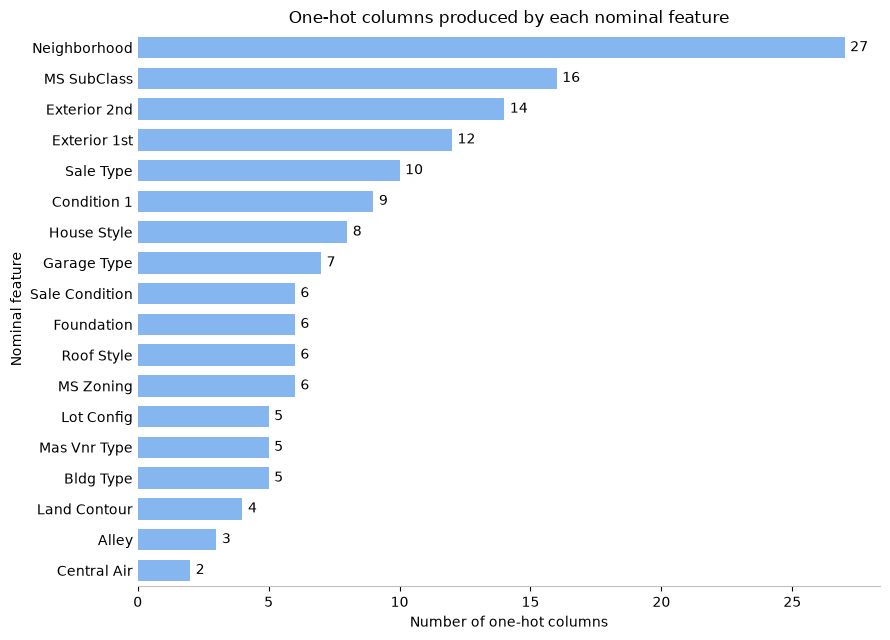

In [3]:
columns_per_feature = pd.Series(
    {feature: sum(col.startswith(f"{feature}_") for col in onehot) for feature in nominal}
).sort_values()
assert columns_per_feature.sum() == len(onehot)

fig, ax = plt.subplots(figsize=(9, 6.5))
bars = ax.barh(columns_per_feature.index, columns_per_feature.values, height=0.7, color=BLUE)
ax.bar_label(bars, padding=4)
ax.set_title("One-hot columns produced by each nominal feature", fontsize=12)
ax.set_xlabel("Number of one-hot columns")
ax.set_ylabel("Nominal feature")
ax.margins(y=0.01)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(AXIS)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

#### Interpretation of the encoding
- **Nominal features** have no real order: the neighborhood `NAmes` is neither more nor less than `OldTown`. One integer per category would invent an order and distances that do not exist, so one-hot encoding gives every category its own 0/1 column. Categories found in fewer than 5 houses share one `infrequent` column.
- **Ordinal features** do have a real order, which is kept as integers, for example `Kitchen Qual`: Po < Fa < TA < Gd < Ex. The integers also assume equal gaps between grades: going from Po to Fa counts as much as going from Gd to Ex.
- **`MS SubClass`** looks numeric, but its codes (20, 60, ...) name dwelling types and are not quantities. `clean()` therefore turns it into text, and it is one-hot encoded like the other nominal features (16 columns).
- **Dimensions:** PCA will start from 205 columns rather than 72, and 151 of them are one-hot columns.

### 2. Missing values

In [4]:
gaps_per_house = X.isna().sum(axis=1)
gaps_per_column = X.isna().sum()
gaps_per_column = gaps_per_column[gaps_per_column > 0].sort_values(ascending=False)

houses_by_gaps = gaps_per_house.value_counts().sort_index().rename_axis("Empty cells").to_frame("Houses")
columns_with_gaps = gaps_per_column.rename_axis("Column").to_frame("Empty cells")
assert houses_by_gaps["Houses"].sum() == len(X)
assert columns_with_gaps["Empty cells"].sum() == gaps_per_house.sum()

display(houses_by_gaps)
print(f"{len(columns_with_gaps)} columns hold {gaps_per_column.sum()} empty cells")
display(columns_with_gaps)

,Houses
Empty cells,
0,2281
1,630
2,12
6,1
11,1


19 columns hold 671 empty cells


,Empty cells
Column,
Lot Frontage,490
Garage Yr Blt,159
Bsmt Exposure,4
Garage Finish,2
BsmtFin Type 2,2
Bsmt Cond,1
Bsmt Qual,1
BsmtFin SF 2,1
Bsmt Unf SF,1


In [5]:
X_complete, y_complete = drop_incomplete(X, y)
X_complete = fill_missing(X_complete)
encoded_complete = make_preprocessor("onehot", min_frequency=5).fit_transform(X_complete, y_complete)

assert X_complete.isna().sum().sum() == 0
assert encoded_complete.columns.equals(encoded.columns)

print(f"{len(X_complete):,} houses, {X_complete.isna().sum().sum()} empty cells")
print(f"{encoded_complete.shape[1]} columns after encoding, the same as before")

2,923 houses, 0 empty cells
205 columns after encoding, the same as before


In [6]:
kept = X.loc[X_complete.index]
dropped_gaps = gaps_per_house.drop(kept.index).sort_values(ascending=False)
incomplete = (gaps_per_house > 0).sum()

garage_gap = kept["Garage Yr Blt"].isna()
garage_years = kept.loc[~garage_gap, ["Garage Yr Blt", "Year Built"]]
no_garage = (kept.loc[garage_gap, "Garage Type"] == "NA").sum()
same_year = (garage_years["Garage Yr Blt"] == garage_years["Year Built"]).mean()
correlation = garage_years["Garage Yr Blt"].corr(garage_years["Year Built"], method="spearman")

neighborhood_median = kept.groupby("Neighborhood", observed=True)["Lot Frontage"].transform("median")
no_known_frontage = kept["Lot Frontage"].isna() & neighborhood_median.isna()
other_gaps = kept.drop(columns=["Garage Yr Blt", "Lot Frontage"]).isna().sum().sum()
neighborhoods = sorted(kept.loc[no_known_frontage, "Neighborhood"].astype(str).unique())

oldest_garage = garage_years["Garage Yr Blt"].min()
filled_years = X_complete.loc[garage_gap, "Garage Yr Blt"]

print(f"Houses dropped: {len(dropped_gaps)}")
for house, count in dropped_gaps.items():
    print(f"  {count} empty cells: {', '.join(X.columns[X.loc[house].isna()])}")
print(f"Most empty cells in a kept house: {gaps_per_house[kept.index].max()}")
print(f"Houses with any empty cell: {incomplete} ({incomplete / len(X):.1%})")
print(f"Empty garage years in the kept houses: {garage_gap.sum()}, of which without a garage: {no_garage}")
print(f"Known garage years equal to Year Built: {same_year:.1%}")
print(f"Spearman correlation of Garage Yr Blt and Year Built: {correlation:.2f}")
print(
    f"Lot Frontage medians by neighborhood: {neighborhood_median.min():.0f} to {neighborhood_median.max():.0f}, "
    f"overall median: {kept['Lot Frontage'].median():.0f}"
)
print(f"Cells filled with the plain median: {other_gaps + no_known_frontage.sum()}")
print(f"Of these Lot Frontage cells: {no_known_frontage.sum()}, in {', '.join(neighborhoods)}")
print(f"Oldest known garage: {oldest_garage:.0f}, oldest filled year: {filled_years.min():.0f}")
print(f"Filled years older than the oldest known garage: {(filled_years < oldest_garage).sum()}")

Houses dropped: 2
  11 empty cells: Bsmt Qual, Bsmt Cond, Bsmt Exposure, BsmtFin Type 1, BsmtFin SF 1, BsmtFin Type 2, BsmtFin SF 2, Bsmt Unf SF, Total Bsmt SF, Bsmt Full Bath, Bsmt Half Bath
  6 empty cells: Garage Yr Blt, Garage Finish, Garage Cars, Garage Area, Garage Qual, Garage Cond
Most empty cells in a kept house: 2
Houses with any empty cell: 644 (22.0%)
Empty garage years in the kept houses: 158, of which without a garage: 157
Known garage years equal to Year Built: 80.3%
Spearman correlation of Garage Yr Blt and Year Built: 0.90
Lot Frontage medians by neighborhood: 21 to 92, overall median: 68
Cells filled with the plain median: 9
Of these Lot Frontage cells: 3, in GrnHill, Landmrk
Oldest known garage: 1895, oldest filled year: 1872
Filled years older than the oldest known garage: 4


#### Interpretation of the missing values
- **Why they are filled:** PCA and k-means calculate with every cell of a house, so they cannot run with empty cells. XGBoost can, which is why `clean()` left them in place.
- **Two houses are dropped:** one has 11 empty cells, its whole basement block, and the other has 6, its whole garage block. Every other house has at most 2. Dropping every incomplete house instead would lose 644 houses (22.0%).
- **`Garage Yr Blt`** is empty mostly because there is no garage: this is true for 157 of the 158 empty cells left. No real year exists for these houses, so `Year Built` is only the closest stand-in. Where the garage year is known, it equals `Year Built` for 80.3% of the houses, and the Spearman correlation of the two columns is 0.90.
- **`Lot Frontage`** is truly unknown: these houses do have a lot, but its frontage was not recorded. The neighborhood median is closer than the overall median, because the medians of the neighborhoods range from 21 to 92 feet, while the overall median is 68.
- **Remaining cells:** the last 9 cells are too few to matter and get the plain median of their column. 3 of them are `Lot Frontage` cells in `GrnHill` and `Landmrk`, which have no known frontage to take a median from.
- **Order:** the fill happens before scaling because 4 filled years are older than the oldest known garage. They lower the minimum of `Garage Yr Blt` from 1895 to 1872, and the scaler has to see this final minimum.

### 3. Min-max scaling

In [7]:
# Fitted on all houses: k-means has no train/test split
scaled = make_scaler().fit_transform(encoded_complete)

empty_cells = scaled.isna().sum().sum()
onehot_unchanged = scaled[onehot].equals(encoded_complete[onehot])

# allclose: the largest value of a column can land a rounding error away from 1
assert np.allclose(scaled.min(), 0) and np.allclose(scaled.max(), 1)
assert empty_cells == 0
assert onehot_unchanged

print(f"Range of all {scaled.shape[1]} columns: {scaled.min().min():.0f} to {scaled.max().max():.0f}")
print(f"Empty cells after scaling: {empty_cells}")
print(f"One-hot columns unchanged: {onehot_unchanged}")

Range of all 205 columns: 0 to 1
Empty cells after scaling: 0
One-hot columns unchanged: True


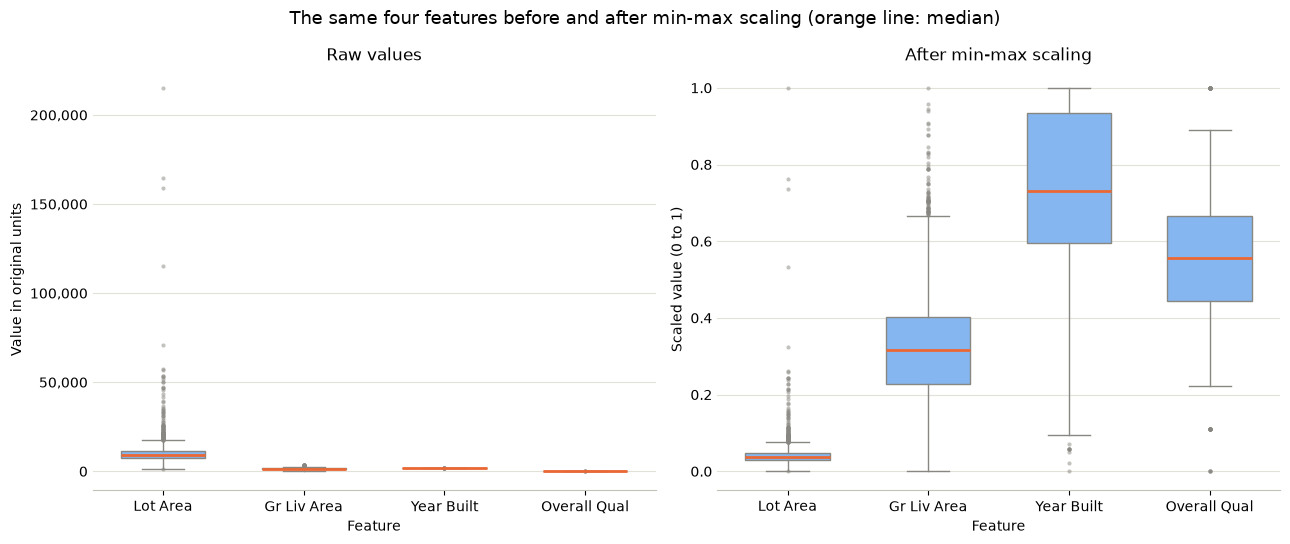

In [8]:
features = ["Lot Area", "Gr Liv Area", "Year Built", "Overall Qual"]
panels = [
    (encoded_complete, "Raw values", "Value in original units"),
    (scaled, "After min-max scaling", "Scaled value (0 to 1)"),
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (data, title, ylabel) in zip(axes, panels):
    ax.boxplot(
        [data[feature] for feature in features],
        tick_labels=features,
        widths=0.6,
        patch_artist=True,
        boxprops={"facecolor": BLUE, "edgecolor": MUTED},
        whiskerprops={"color": MUTED},
        capprops={"color": MUTED},
        medianprops={"color": ORANGE, "linewidth": 2},
        flierprops={"marker": "o", "markersize": 3, "markerfacecolor": MUTED, "markeredgecolor": "none", "alpha": 0.5},
    )
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Feature")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(axis="y", length=0)

axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
fig.suptitle("The same four features before and after min-max scaling (orange line: median)", fontsize=13)
plt.tight_layout()
plt.show()

In [9]:
variance = encoded_complete.var()
lot_area = scaled["Lot Area"]

print(f"Share of Lot Area in the total raw variance: {variance['Lot Area'] / variance.sum():.1%}")
print(f"Largest raw Lot Area: {encoded_complete['Lot Area'].max():,.0f}")
print(f"Houses with a scaled Lot Area below 0.1: {(lot_area < 0.1).mean():.1%}")
print(f"Median scaled Lot Area: {lot_area.median():.3f}")

Share of Lot Area in the total raw variance: 97.6%
Largest raw Lot Area: 215,245
Houses with a scaled Lot Area below 0.1: 98.1%
Median scaled Lot Area: 0.038


#### Interpretation of the min-max scaling
- **Formula:** every column is transformed with `(x - min) / (max - min)`, using the minimum and maximum of that column.
- **Range:** every feature ends up between 0 and 1. The smallest value of a column becomes 0 and the largest becomes 1.
- **Order:** the formula only shifts and stretches a column, so the order of the houses within a feature does not change, and neither does the shape of its distribution.
- **One-hot columns** stay 0/1, because their minimum is already 0 and their maximum already 1.
- **Why it is needed:** distances and variance otherwise follow the features with the largest numbers. Raw `Lot Area` holds 97.6% of the total variance, so a distance between two houses would mostly be a difference in lot size. In the left panel, `Year Built` and `Overall Qual` shrink to flat lines next to it.
- **Sensitivity to outliers:** the minimum and maximum are set by the most extreme houses alone. `Lot Area` reaches 215,245, so 98.1% of the houses land below 0.1 and the median is only 0.038. The feature is on the same scale as the others, but almost all of its houses sit in the lowest tenth of that scale, as the right panel shows.

### 4. Principal component analysis

In [10]:
# One fit is enough: the components kept at a lower threshold are the first ones of this fit
pca = PCA(n_components=0.98, svd_solver="full")
reduced = pca.fit_transform(scaled)
shares = pca.explained_variance_ratio_
cumulative = shares.cumsum()
thresholds = [0.98, 0.95, 0.90, 0.80]
component_counts = {t: int(np.searchsorted(cumulative, t) + 1) for t in thresholds}

above_one_percent = shares > 0.01
assert component_counts[0.98] == pca.n_components_ == reduced.shape[1]

print(f"Columns before / after PCA: {scaled.shape[1]} / {reduced.shape[1]}")
print(f"Variance kept: {cumulative[-1]:.2%}")
print("Shares of the first ten components:")
for number, share in enumerate(shares[:10], start=1):
    print(f"  PC{number}: {share:.2%}")
print(f"First ten components together: {cumulative[9]:.2%}")
print(f"Share of the last component: {shares[-1]:.2%}")
print(f"Components explaining more than 1%: {above_one_percent.sum()}, together {shares[above_one_percent].sum():.2%}")

Columns before / after PCA: 205 / 113
Variance kept: 98.04%
Shares of the first ten components:
  PC1: 13.40%
  PC2: 8.86%
  PC3: 5.50%
  PC4: 4.22%
  PC5: 3.60%
  PC6: 3.05%
  PC7: 2.94%
  PC8: 2.86%
  PC9: 2.78%
  PC10: 2.44%
First ten components together: 49.66%
Share of the last component: 0.06%
Components explaining more than 1%: 25, together 71.74%


In [11]:
counts = list(component_counts.values())
variance_table = pd.DataFrame(
    {
        "Variance kept": [f"{t:.0%}" for t in thresholds],
        "Components": counts,
        "Share of the columns": [f"{count / scaled.shape[1]:.1%}" for count in counts],
    }
)
display(variance_table)
print(f"Extra components from 80% to 98%: {component_counts[0.98] - component_counts[0.80]}")

,Variance kept,Components,Share of the columns
0,98%,113,55.1%
1,95%,82,40.0%
2,90%,59,28.8%
3,80%,36,17.6%


Extra components from 80% to 98%: 77


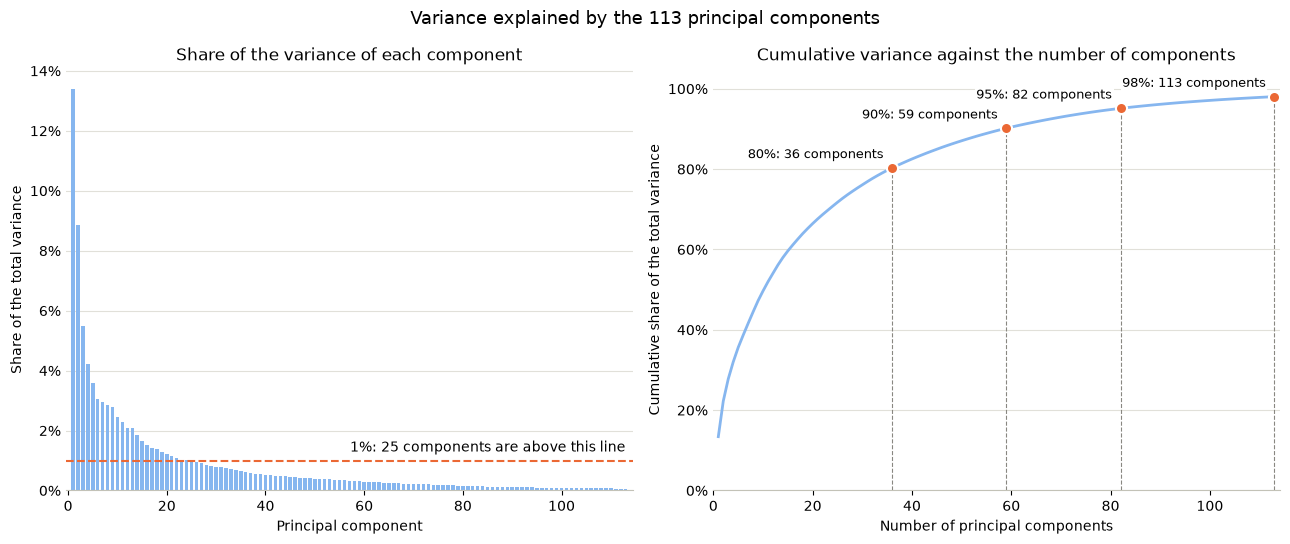

In [12]:
numbers = np.arange(1, len(shares) + 1)

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5.5))

left.bar(numbers, shares, width=0.7, color=BLUE)
left.axhline(0.01, color=ORANGE, linewidth=1.5, linestyle="--")
left.text(numbers[-1], 0.013, f"1%: {above_one_percent.sum()} components are above this line", ha="right")
left.set_title("Share of the variance of each component", fontsize=12)
left.set_xlabel("Principal component")
left.set_ylabel("Share of the total variance")
left.margins(x=0.01)

right.plot(numbers, cumulative, color=BLUE, linewidth=2)
for threshold, count in component_counts.items():
    kept_share = cumulative[count - 1]
    right.vlines(count, 0, kept_share, color=MUTED, linewidth=0.8, linestyle="--")
    right.plot(count, kept_share, "o", color=ORANGE, markersize=8, markeredgecolor="white", markeredgewidth=1.5)
    right.annotate(
        f"{threshold:.0%}: {count} components",
        (count, kept_share),
        xytext=(-6, 7),
        textcoords="offset points",
        ha="right",
        fontsize=9,
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 1},
    )
right.set_title("Cumulative variance against the number of components", fontsize=12)
right.set_xlabel("Number of principal components")
right.set_ylabel("Cumulative share of the total variance")
right.set_ylim(0, 1.05)
right.margins(x=0.01)

for ax in (left, right):
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.0%}"))
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(axis="y", length=0)

fig.suptitle(f"Variance explained by the {len(shares)} principal components", fontsize=13)
plt.tight_layout()
plt.show()

#### Interpretation of the principal components
- **What 98% means:** the reduced data keeps 98% of the original differences between the houses and loses 2% of them. It does not mean that the houses differ by 98%. The components kept reach 98.04%, slightly above the threshold.
- **Features left:** the data goes from 205 columns to 113 (55.1%). Each component is a weighted mix of all 205 columns, so these are 113 new columns, and no original column is simply kept.
- **How quickly the shares fall:** PC1 explains 13.40%, PC2 8.86% and PC3 5.50%. By PC10 the share is down to 2.44%, the first ten components together hold 49.66%, and the last component adds only 0.06%.
- **Components above 1%:** only 25 of the 113 components explain more than 1%, together 71.74%. All the others add less than 1% each, which is the long flat tail in the left panel.
- **Cost of a higher threshold:** 80% takes 36 components, 90% takes 59, 95% takes 82 and 98% takes 113. Going from 80% to 98% takes 77 more components, over twice as many as the first 80% needed, because each later component adds less. The curve in the right panel flattens for the same reason.

### 5. Elbow method

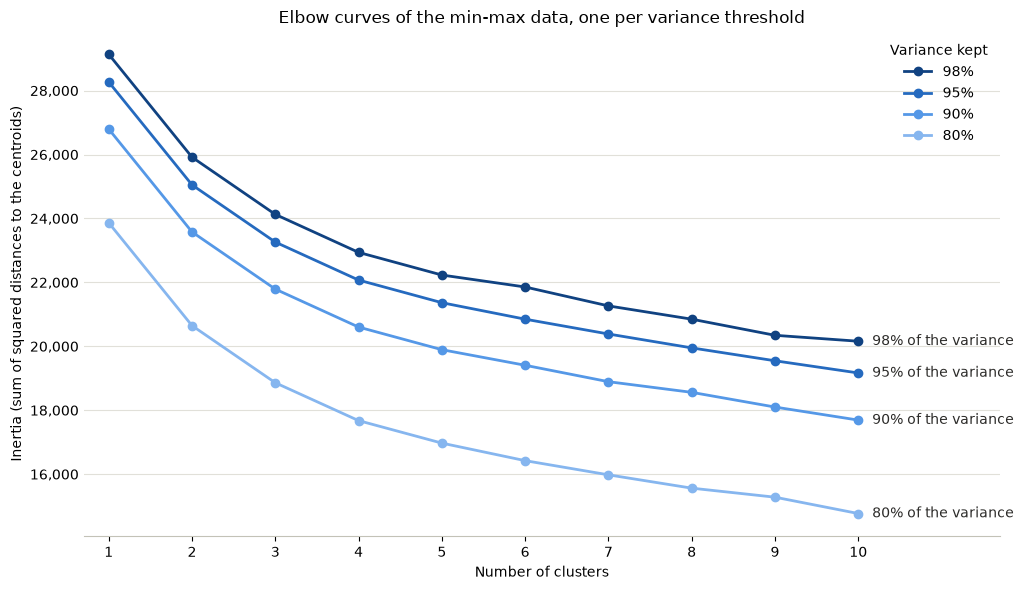

In [13]:
cluster_range = range(1, 11)
inertia = inertia_table(reduced, component_counts, cluster_range)

plot_elbow(inertia, "Elbow curves of the min-max data, one per variance threshold")

In [14]:
drop_per_cluster = inertia.pct_change().dropna().mul(-100).round(1)
drop_per_cluster.index.name = "Cluster added"

kept = pd.Series({f"{t:.0%}": cumulative[count - 1] for t, count in component_counts.items()})
height = pd.DataFrame(
    {
        "Inertia with 1 cluster": inertia.loc[1],
        "Compared with 98%": inertia.loc[1] / inertia.loc[1, "98%"],
        "Variance kept compared with 98%": kept / kept["98%"],
    }
)

print("Inertia:")
display(inertia.round(0).astype(int))
print("Percentage drop in inertia when one more cluster is added:")
display(drop_per_cluster)
print("Height of the curves:")
display(height.round(3))

Inertia:


,98%,95%,90%,80%
Clusters,,,,
1,29136,28269,26796,23864
2,25917,25050,23578,20646
3,24127,23261,21789,18859
4,22939,22072,20602,17675
5,22230,21365,19894,16971
6,21856,20849,19407,16423
7,21264,20385,18893,15979
8,20849,19951,18560,15562
9,20344,19547,18100,15280


Percentage drop in inertia when one more cluster is added:


,98%,95%,90%,80%
Cluster added,,,,
2,11.0,11.4,12.0,13.5
3,6.9,7.1,7.6,8.7
4,4.9,5.1,5.4,6.3
5,3.1,3.2,3.4,4.0
6,1.7,2.4,2.5,3.2
7,2.7,2.2,2.6,2.7
8,2.0,2.1,1.8,2.6
9,2.4,2.0,2.5,1.8
10,0.9,2.0,2.3,3.3


Height of the curves:


,Inertia with 1 cluster,Compared with 98%,Variance kept compared with 98%
98%,29136.037,1.000,1.000
95%,28269.176,0.970,0.970
90%,26796.391,0.920,0.920
80%,23864.241,0.819,0.819


#### Interpretation of the elbow curves
- **Inertia:** k-means gives every cluster a centroid, the mean point of its houses. Inertia adds up the squared distance from every house to its own centroid, so a small inertia means that the houses sit close to the center of their group.
- **Why it always falls:** a further centroid can only bring houses closer to a center, so inertia drops with every added cluster, even in data without any real groups. At 90% it falls from 26,796 with one cluster to 17,691 with ten. The lowest value therefore says nothing about the right number of clusters. The elbow method looks for the point where one more cluster stops paying off.
- **Where the curve bends:** at 90% the second cluster removes 12.0% of the inertia, the third 7.6%, the fourth 5.4% and the fifth 3.4%. From the sixth cluster on, each addition removes between 1.8% and 2.6%, so the curve turns flat after 5 clusters. The bend is gradual and has no sharp corner, which already hints that the houses do not fall into clearly separate groups.
- **Uneven drops:** values such as 1.7% followed by 2.7% at 98% show that k-means finds a slightly better or worse solution for each number of clusters, so single values after 5 should not be over-read.
- **Why lower thresholds sit lower:** with one cluster, inertia is the total variance of the kept components multiplied by the number of houses. Dropping components removes variance, so the 80% curve starts at 23,864 instead of 29,136, which is 0.819 of it. The last table shows that this is exactly the variance kept compared with 98%. The curve is lower because less is being measured, not because the clusters are tighter.
- **Shape, not height:** for that reason the curves cannot be compared by their level. Their shape is nearly the same: the fifth cluster removes between 3.1% and 4.0% at all four thresholds.

### 6. Silhouette analysis

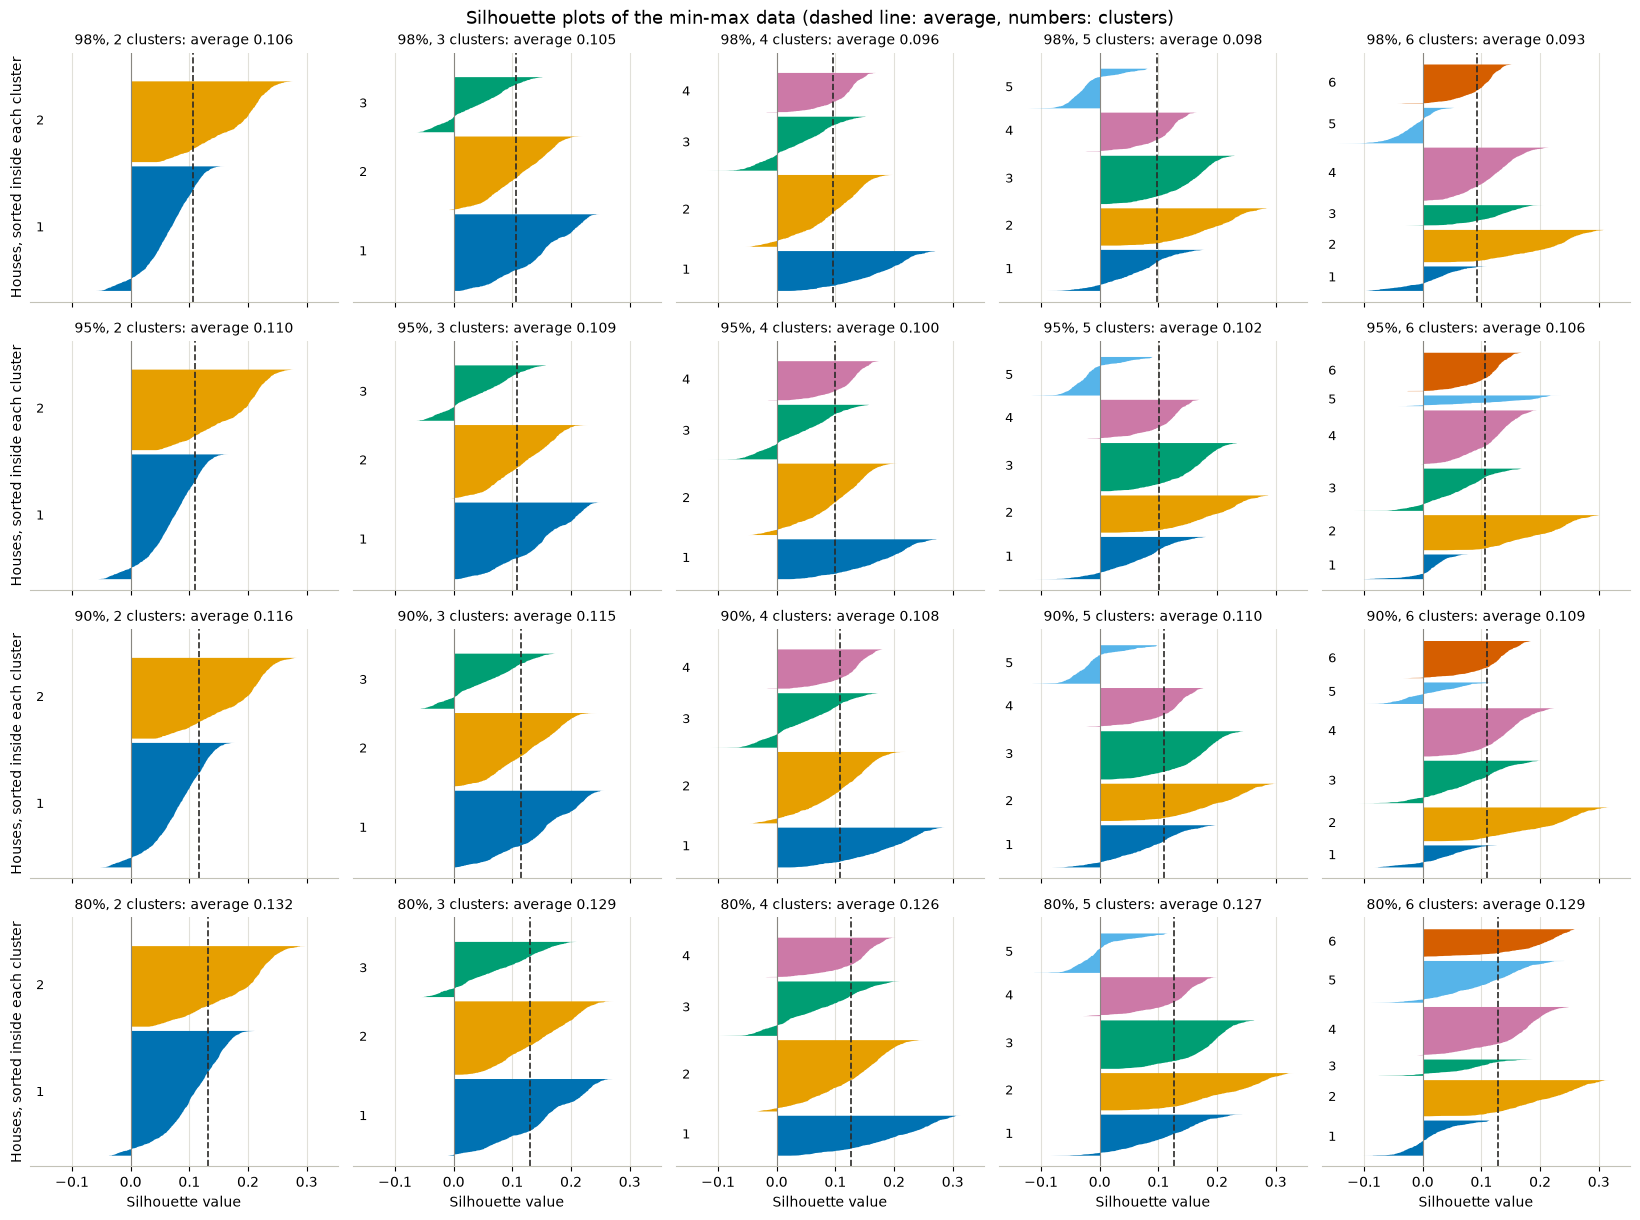

In [15]:
plot_silhouettes(
    reduced,
    component_counts,
    range(2, 7),
    "Silhouette plots of the min-max data (dashed line: average, numbers: clusters)",
)

In [16]:
silhouette = silhouette_table(reduced, component_counts, range(2, 9))

print("Average silhouette:")
display(silhouette.round(3))
print("Number of clusters with the highest average silhouette:")
print(silhouette.idxmax().to_string())

Average silhouette:


,98%,95%,90%,80%
Clusters,,,,
2,0.106,0.110,0.116,0.132
3,0.105,0.109,0.115,0.129
4,0.096,0.100,0.108,0.126
5,0.098,0.102,0.110,0.127
6,0.093,0.106,0.109,0.129
7,0.086,0.098,0.106,0.127
8,0.090,0.091,0.093,0.126


Number of clusters with the highest average silhouette:
98%    2
95%    2
90%    2
80%    2


#### Interpretation of the silhouette analysis
- **Silhouette value:** for one house, `a` is its mean distance to the other houses of its cluster and `b` its mean distance to the houses of the nearest other cluster. The value `(b - a) / max(a, b)` is close to 1 if the house sits deep inside its cluster, close to 0 if it lies on the border between two clusters, and negative if it is closer to the other cluster.
- **Reading the figure:** every colored shape is one cluster, with its houses sorted by value. A thick shape is a large cluster, a shape reaching far to the right holds well-placed houses, and whatever lies left of 0 is closer to another cluster. The dashed line is the average over all houses.
- **Scores near 0.1:** all averages lie between 0.086 and 0.132, on a scale that ends at 1. A value of 0.1 means that a house is only about 10% closer to its own cluster than to the next one. The clusters overlap heavily: the houses form one connected cloud with denser regions, not separate islands. k-means still divides that cloud, but its borders do not follow natural gaps.
- **Number of clusters:** the average is highest at 2 clusters at every threshold. At 90% it reads 0.116, followed by 0.115 for 3 clusters and 0.110 for 5. The gap is small, so the silhouette prefers few clusters only weakly. It does not fall steadily either, because 5 clusters score slightly above 4 at all four thresholds.
- **The weakest cluster:** with 5 clusters, cluster 5 reaches furthest below 0 at every threshold. The scatter plots below show why: it lies between the four others.
- **Thresholds:** the average rises as components are dropped, at 5 clusters from 0.098 at 98% to 0.127 at 80%. The later components add small differences in all directions, which push `a` and `b` closer together. This is an effect on the measure, and the final models below check whether the houses really change clusters.

### 7. Choice of the number of clusters

In [17]:
test_threshold = 0.90
test_data = reduced[:, : component_counts[test_threshold]]
seeds = range(6)

rows = []
for k in range(2, 8):
    runs = [KMeans(n_clusters=k, n_init=N_INIT, random_state=seed).fit_predict(test_data) for seed in seeds]
    pair_scores = [adjusted_rand_score(first, second) for first, second in combinations(runs, 2)]
    rows.append(
        {
            "Clusters": k,
            "Seed pairs": len(pair_scores),
            "Mean agreement": np.mean(pair_scores),
            "Lowest agreement": np.min(pair_scores),
            "Inertia drop (%)": drop_per_cluster.loc[k, "90%"],
            "Average silhouette": silhouette.loc[k, "90%"],
            "Cluster sizes (seed 0)": sorted(np.bincount(runs[0]).tolist()),
        }
    )

choice = pd.DataFrame(rows).set_index("Clusters")
with pd.option_context("display.max_colwidth", None):
    display(choice.round(3))

,Seed pairs,Mean agreement,Lowest agreement,Inertia drop (%),Average silhouette,Cluster sizes (seed 0)
Clusters,,,,,,
2,15,0.998,0.996,12.0,0.116,"[1148, 1775]"
3,15,0.999,0.998,7.6,0.115,"[786, 1046, 1091]"
4,15,0.993,0.988,5.4,0.108,"[563, 565, 775, 1020]"
5,15,0.992,0.982,3.4,0.110,"[531, 552, 554, 602, 684]"
6,15,0.820,0.617,2.5,0.109,"[233, 391, 488, 519, 600, 692]"
7,15,0.696,0.496,2.6,0.106,"[149, 236, 416, 423, 426, 597, 676]"


In [18]:
n_clusters = 5

rows = []
for seed in [*seeds, SEED]:
    model = KMeans(n_clusters=n_clusters, n_init=N_INIT, random_state=seed).fit(test_data)
    rows.append({"Seed": seed, "Inertia": model.inertia_, "Cluster sizes": sorted(np.bincount(model.labels_).tolist())})

print(f"Chosen number of clusters: {n_clusters}")
print(f"Runs at {test_threshold:.0%} of the variance with each seed:")
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows).set_index("Seed").round(1))

Chosen number of clusters: 5
Runs at 90% of the variance with each seed:


,Inertia,Cluster sizes
Seed,,
0,19894.5,"[531, 552, 554, 602, 684]"
1,19894.1,"[530, 555, 564, 585, 689]"
2,19894.1,"[530, 554, 563, 587, 689]"
3,19894.1,"[531, 555, 561, 588, 688]"
4,19894.1,"[531, 554, 562, 587, 689]"
5,19894.1,"[530, 554, 564, 584, 691]"
42,19894.5,"[531, 549, 555, 601, 687]"


#### Interpretation of the number of clusters
- **What was tried:** k-means starts from random positions, and a seed fixes that randomness. At 90% of the variance, each number of clusters from 2 to 7 was fitted with six seeds. The 15 pairs of runs were then compared with the **adjusted Rand index**, which says how similar two groupings of the same houses are, whatever numbers the clusters carry: 1 is the same grouping, 0 is what chance gives.
- **What came out:** from 2 to 5 clusters the runs agree almost completely, with a mean of at least 0.992 and a lowest pair of 0.982 at 5 clusters. At 6 clusters the mean falls to 0.820 and the lowest pair to 0.617, at 7 clusters to 0.696 and 0.496. There the result depends on the random start, so it is not a property of the houses.
- **Choice:** 5 clusters, for four reasons.
    - **Elbow:** the fifth cluster still removes 3.4% of the inertia, and the additions after it remove at most 2.6%.
    - **Stability:** 5 is the largest number of clusters that gives the same grouping from every start. The seed table shows inertias from 19,894.1 to 19,894.5 and cluster sizes that differ by at most 18 houses.
    - **Detail:** 2 clusters only halve the houses, into 1,148 and 1,775. 5 clusters give groups of similar size, from 531 to 684 houses in the seed 0 run.
    - **Comparability:** the same number of clusters in notebooks 08, 08.1, 08.2 and 08.3 means that a difference between them comes from the data preparation and not from the number of clusters.
- **Evidence against it:** the silhouette prefers 2 clusters (0.116) and 3 clusters (0.115) to 5 clusters (0.110), although only by a small gap. The elbow is gradual, so 5 is a reasonable reading of the curve and not a sharp result.
- **Rejected:** 2 and 3 clusters score slightly better on the silhouette, but say little about the houses. 4 clusters are just as stable, but the next cluster still removes 3.4%. 6 and 7 clusters depend on the seed.

### 8. Final models and cluster scatter plots

In [19]:
models = fit_models(reduced, component_counts, n_clusters)
labels_at_98 = models[0.98].labels_

rows = []
for threshold, model in models.items():
    count = component_counts[threshold]
    values = silhouette_samples(reduced[:, :count], model.labels_)
    sizes = np.bincount(model.labels_)
    rows.append(
        {
            "Variance kept": f"{threshold:.0%}",
            "Components": count,
            **{f"Cluster {number}": size for number, size in enumerate(sizes, start=1)},
            "Inertia": model.inertia_,
            "Average silhouette": values.mean(),
            "Negative silhouette": (values < 0).mean(),
            "Houses not in their 98% cluster": (model.labels_ != labels_at_98).sum(),
        }
    )

final_models = pd.DataFrame(rows).set_index("Variance kept")
display(final_models.round(3))

,Components,Cluster 1,Cluster 2,Cluster 3,Cluster 4,Cluster 5,Inertia,Average silhouette,Negative silhouette,Houses not in their 98% cluster
Variance kept,,,,,,,,,,
98%,113,585,531,688,554,565,22230.073,0.098,0.184,0
95%,82,602,530,686,555,550,21364.576,0.102,0.181,20
90%,59,601,531,687,555,549,19894.456,0.110,0.169,19
80%,36,585,531,690,555,562,16971.212,0.127,0.139,10


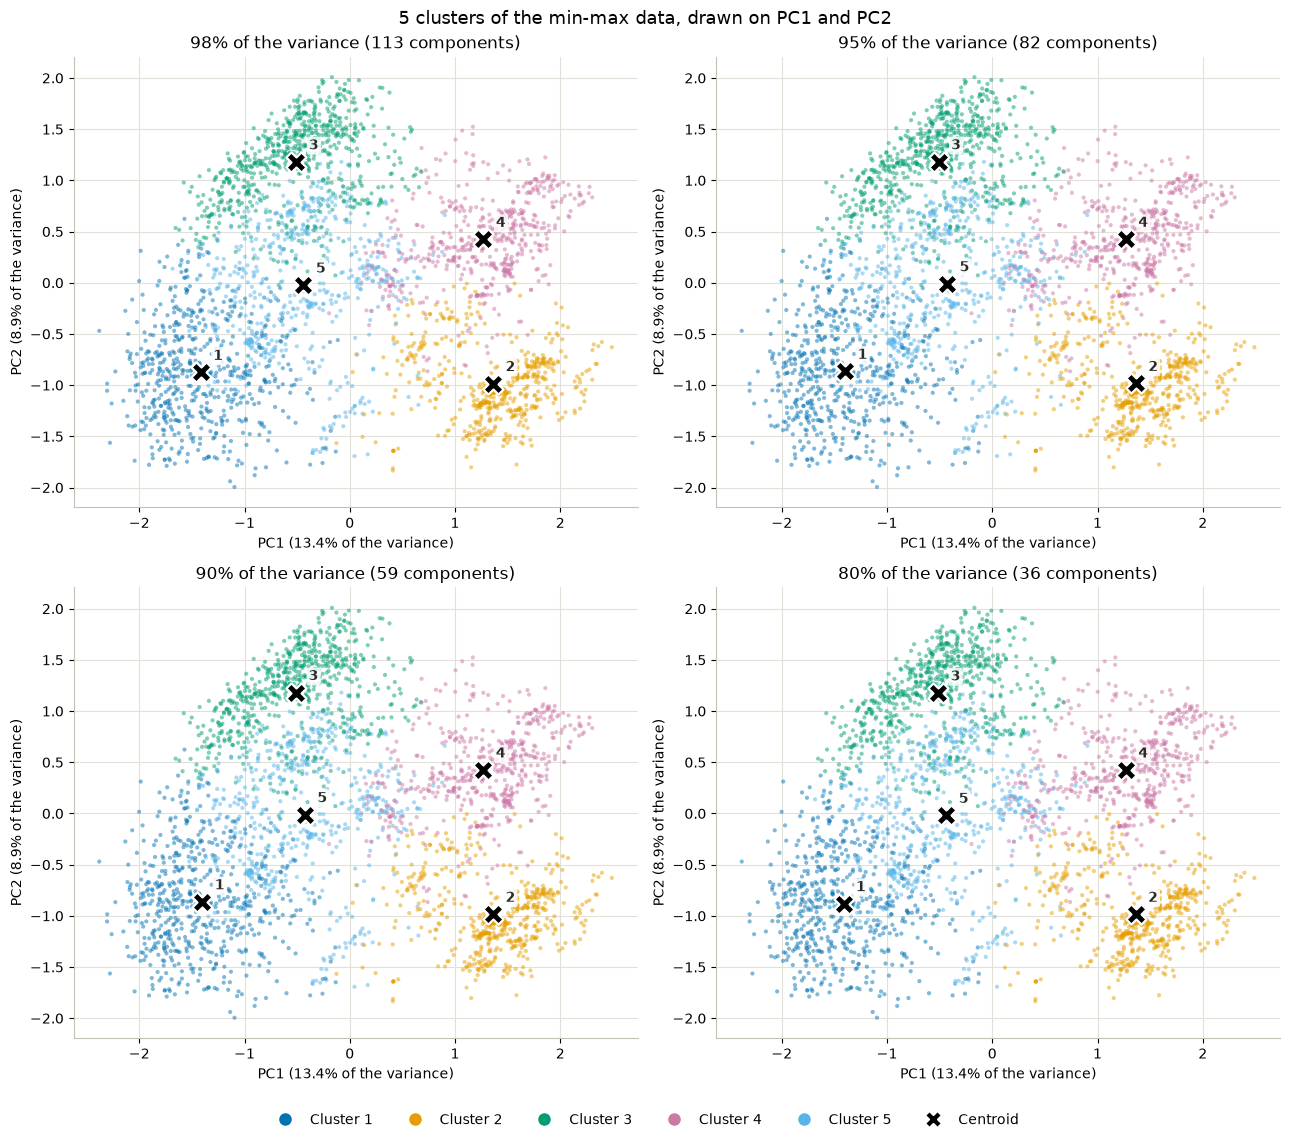

In [20]:
panels = {
    f"{threshold:.0%} of the variance ({component_counts[threshold]} components)": (pca, reduced, model)
    for threshold, model in models.items()
}
plot_clusters(panels, f"{n_clusters} clusters of the min-max data, drawn on PC1 and PC2")

In [21]:
threshold_agreement = agreement_table({f"{t:.0%}": model.labels_ for t, model in models.items()})
pair_scores = threshold_agreement.to_numpy()[np.triu_indices(len(threshold_agreement), k=1)]

centroid_shift = max(
    np.abs(model.cluster_centers_[:, :2] - models[0.98].cluster_centers_[:, :2]).max() for model in models.values()
)
visible = pd.Series({f"{t:.0%}": shares[:2].sum() / cumulative[count - 1] for t, count in component_counts.items()})

print("Adjusted Rand index between the thresholds:")
display(threshold_agreement.round(3))
print(f"Lowest agreement between two thresholds: {pair_scores.min():.3f}")
print(f"Largest move of a centroid on PC1 or PC2 compared with 98%: {centroid_shift:.3f}")
print(f"Standard deviation of the houses on PC1 / PC2: {reduced[:, 0].std():.3f} / {reduced[:, 1].std():.3f}")
print("Share of the kept variance that PC1 and PC2 show:")
print(visible.map("{:.1%}".format).to_string())

Adjusted Rand index between the thresholds:


,98%,95%,90%,80%
98%,1.000,0.983,0.984,0.991
95%,0.983,1.000,0.996,0.985
90%,0.984,0.996,1.000,0.984
80%,0.991,0.985,0.984,1.000


Lowest agreement between two thresholds: 0.983
Largest move of a centroid on PC1 or PC2 compared with 98%: 0.018
Standard deviation of the houses on PC1 / PC2: 1.167 / 0.949
Share of the kept variance that PC1 and PC2 show:
98%    22.7%
95%    23.4%
90%    24.7%
80%    27.7%


#### Interpretation of the final models
- **Are there differences?** Hardly any. The four panels look almost the same. At most 20 of the 2,923 houses sit in a different cluster than at 98%, the sizes of a cluster differ by at most 17 houses (cluster 1, 585 to 602), and the lowest adjusted Rand index between two thresholds is 0.983.
- **PC1 and PC2 are the same columns:** the four datasets are the first 113, 82, 59 and 36 columns of one PCA fit. Every house therefore has the same position in all four panels, and only its color and the centroids could move. The centroids move by at most 0.018 on PC1 or PC2, while the houses have a standard deviation of 1.167 and 0.949 on these axes.
- **Why so little moves:** the components dropped between 98% and 80% are 77 small ones, which together hold 18 percentage points of the variance. Distances between houses are decided mostly by the large components that all four datasets share.
- **No steady trend:** the 80% model is closer to the 98% model (10 houses differ, index 0.991) than the 95% model is (20 houses, index 0.983). The differences between the thresholds are of the same size as the differences between seeds, whose mean agreement was 0.992.
- **What does change:** inertia falls from 22,230 to 16,971, the average silhouette rises from 0.098 to 0.127 and the share of houses with a negative silhouette falls from 18.4% to 13.9%. As the houses keep their clusters, these numbers improve because fewer components are measured, not because better groups were found.
- **Why the clusters overlap in the picture:** k-means used all kept components, while the plot shows only two of them. PC1 and PC2 hold 24.7% of the variance kept at 90%, so two houses that look close here can be far apart in the other 57 components. The crosses are the centroids reduced to their first two coordinates, and cluster 5 sits in the middle of the cloud, in line with its weak silhouette.